# DBSCAN 

In [4]:
print("What is DBSCAN ? ")
print("DBSCAN is an unsupervised, density-based clustering algorithm that groups together data points \n that are closely packed and identifies points in sparse regions as noise or outliers.")

What is DBSCAN ? 
DBSCAN is an unsupervised, density-based clustering algorithm that groups together data points 
 that are closely packed and identifies points in sparse regions as noise or outliers.


# for more info click below the link 

https://docs.google.com/document/d/13U2jp89L_a3GDB1a_rqPkyVeOnrCVXJCa2HTPdnF-t8/edit?usp=sharing

# notes and interview question and answer

https://docs.google.com/document/d/1sPEk2xdnxXlljkGz7mpxzMhJqqrhnRwj9WqpIIaFvVo/edit?usp=sharing


# Coding

# Import libraries 

In [11]:
# NumPy → numerical calculations
import numpy as np

# Pandas → data manipulation
import pandas as pd

# Matplotlib → visualization
import matplotlib.pyplot as plt

# make_moons → creates a non-linear clustering dataset
from sklearn.datasets import make_moons

# StandardScaler → scales the features
from sklearn.preprocessing import StandardScaler

# DBSCAN → density-based clustering algorithm
from sklearn.cluster import DBSCAN

# Silhouette Score → evaluates clustering quality
from sklearn.metrics import silhouette_score

# Create the dataset 

In [2]:
X, y = make_moons(
    n_samples=500,                        # Generate 500 observations
    noise=0.08,                           # Add a small amount of noise
    random_state=42                       # Make dataset generation reproducible
)

# Visualize the raw data 

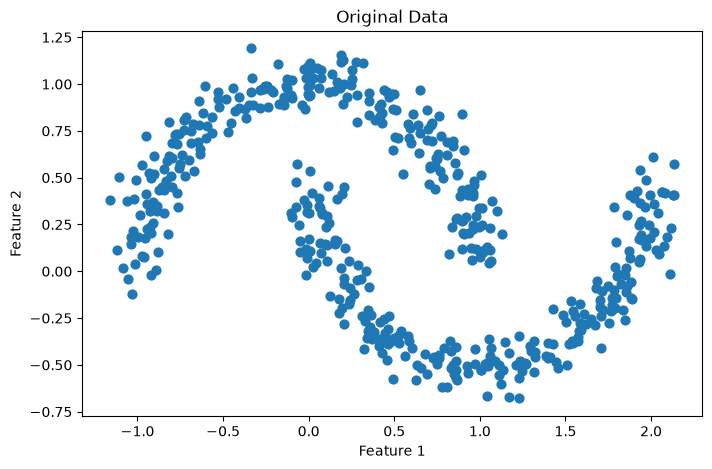

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0],                              # First feature
    X[:, 1],                              # Second feature
    s=40                                  # Point size
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Original Data")

plt.show()

# Scale the data 

`DBSCAN uses distance, so scaling is important when features have different scales . `

In [12]:
scaler = StandardScaler()                # Creates the standardization object

X_scaled = scaler.fit_transform(
    X                                     # Standardizes both features
)

# Train DBSCAN

In [14]:
dbscan = DBSCAN(
    eps=0.3,                              # Radius used to define a neighborhood
    min_samples=5,                        # Minimum points needed to form a dense region
    metric="euclidean"                    # Distance measure between points
)

clusters = dbscan.fit_predict(
    X_scaled                             # Learn clusters from the feature data
)

# Notice again there is no y . because this is a unsupervised learning. 

# Look at the cluster labels .

In [15]:
print(np.unique(clusters))               # Shows all discovered cluster IDs
# -1 is Noise
# 0 is - cluster 0 
# 1 is - cluster 1

[0 1]


# Count the cluster 

In [7]:
n_clusters = len(
    set(clusters) - {-1}                 # Remove -1 because -1 represents noise
)

print("Number of clusters:", n_clusters)

Number of clusters: 2


# Count noise points

In [8]:
n_noise = np.sum(
    clusters == -1                        # Counts observations classified as noise
)

print("Number of noise points:", n_noise)

Number of noise points: 0


# Visualize DBSCAN

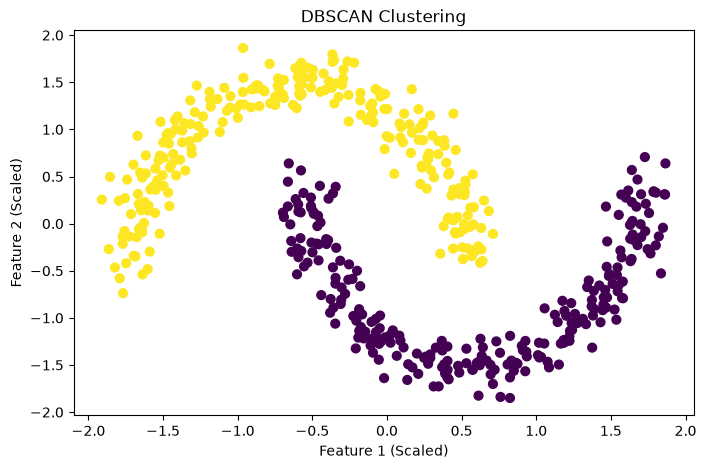

In [9]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],                      # First feature
    X_scaled[:, 1],                      # Second feature
    c=clusters,                          # Color according to DBSCAN cluster
    s=40                                 # Point size
)

plt.xlabel("Feature 1 (Scaled)")
plt.ylabel("Feature 2 (Scaled)")
plt.title("DBSCAN Clustering")

plt.show()

# Evaluate DBSCAN 
`We can use Silhouette Score, just like K-Means and Hierarchical Clustering.`

`But there is an important issue: `

`If DBSCAN produces only one cluster, or all points are noise, silhoutte score can't be meaningfully calculated.`

In [16]:
unique_clusters = set(clusters) - {-1}   # Remove the noise label

if len(unique_clusters) > 1:

    score = silhouette_score(
        X_scaled,                          # Feature data
        clusters                           # Cluster assignments
    )

    print("Silhouette Score:", score)

else:

    print("Silhouette Score cannot be calculated.")

Silhouette Score: 0.38355256771289353


# Hyperparameter experiment 

`This is the most important part of DBSCAN.`

`DBSCAN has 2 particularly important parameters:`

In [20]:
# eps
# min_samples

# Experiment - eps , eps control the neighborhood radius . 

# Small eps
#   ↓
# Small neighborhoods
#  ↓
# fewer points considered connected
#   ↓
# More noise / potentially more clusters


# While ANother mean 
#
# Large eps
#   ↓
# Larger neighborhoods
#  ↓
# more points become connected
#   ↓
# Clusters can merge

In [21]:
eps_values = [0.1, 0.2, 0.3, 0.4, 0.5]

for eps in eps_values:

    model = DBSCAN(
        eps=eps,                           # Test a different neighborhood radius
        min_samples=5,                     # Keep min_samples fixed
        metric="euclidean"                 # Euclidean distance
    )

    labels = model.fit_predict(
        X_scaled                           # Perform DBSCAN clustering
    )

    n_clusters = len(
        set(labels) - {-1}                 # Count clusters excluding noise
    )

    n_noise = np.sum(
        labels == -1                       # Count noise observations
    )

    print(
        f"eps={eps} | clusters={n_clusters} | noise={n_noise}"
    )

eps=0.1 | clusters=27 | noise=132
eps=0.2 | clusters=2 | noise=4
eps=0.3 | clusters=2 | noise=0
eps=0.4 | clusters=2 | noise=0
eps=0.5 | clusters=1 | noise=0


In [ ]:
# Experiment 2 - min_samples 

# now keep eps fixed and ahange min_samples . 


min_samples_values = [3, 5, 10, 15, 20]

for min_samples in min_samples_values:

    model = DBSCAN(
        eps=0.3,                           # Keep neighborhood radius fixed
        min_samples=min_samples,           # Test different density requirements
        metric="euclidean"                 # Euclidean distance
    )

    labels = model.fit_predict(
        X_scaled                           # Perform clustering
    )

    n_clusters = len(
        set(labels) - {-1}                 # Count clusters excluding noise
    )

    n_noise = np.sum(
        labels == -1                       # Count noise points
    )

    print(
        f"min_samples={min_samples} | "
        f"clusters={n_clusters} | "
        f"noise={n_noise}"
    )

    # What happens as min_samples increase 
    # The density requirement become stricter. 


# Higher min_samples
#       ↓
# Harder to become a core point
#      ↓
# More points may become noise


min_samples=3 | clusters=2 | noise=0
min_samples=5 | clusters=2 | noise=0
min_samples=10 | clusters=2 | noise=1
min_samples=15 | clusters=2 | noise=2
min_samples=20 | clusters=2 | noise=9
